In [ ]:
### ABOUT THIS NOTEBOOK!

# this notebook is used to create classification model with detail information
# 1. Input grid data (every grid have 24 variables and label (0 or 1)
# 2. Split train and test data with undersampling and k-fold approach
# 3. Train data with random forest classification algorithm and finding best parameters with bayessian optimization (Optuna)
# 4. Model evaluation
# 5. Explainable AI with feature importance, partial dependance plot (PDP), and Shapely Additive exPlanation (SHAP)

# REQUIREMENT!
# please install those library first before running the code.

# pip install numpy
# pip install pandas
# pip install geopandas
# pip install matplotlib
# pip install scikit-learn
# pip install optuna
# pip install shap
# pip install spatialkfold
# pip install esda
# pip install libpysal
# pip install splot

# 01 Import the following library.

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import optuna

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    classification_report, roc_curve, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.inspection import PartialDependenceDisplay
from spatialkfold.blocks import spatial_blocks

import shap

In [86]:
# 02 Import main data (data included 24 variables and labels).
data = gpd.read_file("../data/main_data.gpkg")

In [87]:
# 03 Data cleaning and preparation.
df = data.rename(columns={

    'x1mean': 'X1',         # VAR 01 = Night Time Light (NTL) density
    'x2mean': 'X2',         # VAR 02 = Population density.

    'distance_min': 'X3',   # VAR 03 = Distance to nearest road network.
    'x4_dist': 'X4',        # VAR 04 = Distance to nearest jaklingko stop.
    'x5_dist': 'X5',        # VAR 05 = Distance to nearest busway stop.
    'x6_dist': 'X6',        # VAR 06 = Distance to nearest railway station.
    'x7_dist': 'X7',        # VAR 07 = Distance to nearest fuel station. 

    'x8_dist': 'X8',        # VAR 08 = Distance to nearest mall. 
    'x9_dist': 'X9',        # VAR 09 = Distance to nearest campus. 
    'x10_dist': 'X10',      # VAR 10 = Distance to nearest office.

    '_x11mean': 'X11',      # VAR 11 = Government institute density.
    '_x12mean': 'X12',      # VAR 12 = Restaurant density.
    'x13mean': 'X13',       # VAR 13 = Fast food density.
    'x14mean': 'X14',       # VAR 14 = School density.
    'x15mean': 'X15',       # VAR 15 = Shopping store density.
    'x16mean': 'X16',       # VAR 16 = Sport facilities density.
    '_x17mean': 'X17',      # VAR 17 = Leisure facilities density.
    'x18mean': 'X18',       # VAR 18 = Healthcare facilities density.
    'x19mean': 'X19',       # VAR 19 = Tourism spot density.
    'x20mean': 'X20',       # VAR 20 = Hotel density.

    'x21mean': 'X21',       # VAR 21 = Apartement density.
    'fid_count': 'X22',     # VAR 22 = Building count.
    'luas_mean': 'X23',     # VAR 23 = Average building area.
    'x24mean': 'X24'        # VAR 24 = Competitor count.
})

print(df.columns)

features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13',
    'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'X24']


Index(['id', 'left', 'top', 'right', 'bottom', 'row_index', 'col_index',
       'luas', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'x17mean', 'X18',
       'X19', 'X20', 'X21', 'X24', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10',
       'X1', 'X2', 'X3', 'X23', 'kedai_kopimean', 'fid_count_2', 'label',
       'X22', 'X17', 'geometry'],
      dtype='object')


In [88]:
# 04 Information for grid's label distribution.
print(df.groupby('label').size())

# 05 Splitting data by label (80:20 ratio) and undersampling.
df_pos = df[df["label"] == 1]
df_neg = df[df["label"] == 0]

df_neg_balanced = df_neg.sample(n=len(df_pos), random_state=42)

df_balanced = pd.concat([df_pos, df_neg_balanced])
df_balanced = (
    df_balanced
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)
assert isinstance(df_balanced, gpd.GeoDataFrame)

total = len(df_balanced)
pos = df_balanced['label'].sum()
neg = (df_balanced['label']==0).sum()

print(f"Total data: {total} | Positive: {pos} | Negative: {neg}")

label
0    16433
1      352
dtype: int64
Total data: 704 | Positive: 352 | Negative: 352


In [89]:
# 06 Hyperparameter tuning with bayessian optimization (Optuna)
trial = df_balanced.drop(columns='geometry')
X = trial[features]
y = trial['label']

def objective(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_categorical('max_depth', [None, 5,6,7,8,9, 10]),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 5),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2']),
        'random_state': 42
    }

    rf = RandomForestClassifier(**param)
    cv_scores = cross_val_score(rf, X, y, cv=5, scoring='accuracy', n_jobs=-1)
    return cv_scores.mean()

if __name__ == "__main__":
    study = optuna.create_study(
        direction='maximize',
        study_name="RF_Coffee_Shop_Optimization"
    )
    study.optimize(objective, n_trials=20) # NOTES = n-trial is adjustabel
    
    best_params = study.best_params
    print(f"Best F1: {study.best_value:.4f}")
    print(f"Best params: {best_params}")

[I 2026-11-01 14:47:03,320] A new study created in memory with name: RF_Coffee_Shop_Optimization
[I 2026-11-01 14:47:13,425] Trial 0 finished with value: 0.8423404255319149 and parameters: {'n_estimators': 142, 'max_depth': 8, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': 'log2'}. Best is trial 0 with value: 0.8423404255319149.
[I 2026-11-01 14:47:21,045] Trial 1 finished with value: 0.8338196555217833 and parameters: {'n_estimators': 156, 'max_depth': 6, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.8423404255319149.
[I 2026-11-01 14:47:31,842] Trial 2 finished with value: 0.8494224924012158 and parameters: {'n_estimators': 328, 'max_depth': 9, 'min_samples_split': 3, 'min_samples_leaf': 2, 'max_features': 'log2'}. Best is trial 2 with value: 0.8494224924012158.
[I 2026-11-01 14:47:39,623] Trial 3 finished with value: 0.8366666666666666 and parameters: {'n_estimators': 215, 'max_depth': 7, 'min_samples_split': 3,

Best F1: 0.8494
Best params: {'n_estimators': 328, 'max_depth': 9, 'min_samples_split': 3, 'min_samples_leaf': 2, 'max_features': 'log2'}


In [90]:
# 07 Spatial k-fold split
folds_gdf = spatial_blocks(gdf=df_balanced, width=3000, height=3000, nfolds=5,random_state=42)

print(f"Blocks count : {len(folds_gdf)}")
print(f"Fold distribution :\n{folds_gdf['folds'].value_counts().sort_index()}")

df_balanced = df_balanced.reset_index(drop=True)

df_with_folds = gpd.sjoin(df_balanced,folds_gdf[['geometry', 'folds']], how='left', predicate='within')
df_with_folds = df_with_folds[~df_with_folds.index.duplicated(keep='first')]

print(f"\nTotal data after joined {len(df_with_folds)}")
print(f"Fold distribution:\n{df_with_folds['folds'].value_counts().sort_index()}")

Blocks count : 26
Fold distribution :
folds
1    6
2    5
3    5
4    5
5    5
Name: count, dtype: int64

Total data after joined 704
Fold distribution:
folds
1.0    124
2.0    134
3.0     79
4.0    185
5.0    155
Name: count, dtype: int64


In [91]:
# 08 Random forest classification model training
rf = RandomForestClassifier(
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    random_state=42,
    min_samples_leaf=best_params['min_samples_leaf'],
    min_samples_split=best_params['min_samples_split'],
    max_features=best_params['max_features']
)

acc_scores, prec_scores, rec_scores, f1_scores, auc_scores = [], [], [], [], []
all_y_test = []
all_y_pred = []
all_y_prob = []

for fold_id in sorted(df_with_folds['folds'].unique()):

    test_idx  = df_with_folds[df_with_folds['folds'] == fold_id].index
    train_idx = df_with_folds[df_with_folds['folds'] != fold_id].index
    train = df_with_folds.loc[train_idx]
    test  = df_with_folds.loc[test_idx]

    label_dist = test['label'].value_counts().to_dict()
    if len(label_dist) < 2: continue

    X_train = train[features]
    y_train = train["label"]
    X_test  = test[features]
    y_test  = test["label"]

    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_test)
    y_prob = rf.predict_proba(X_test)[:, 1]

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    auc  = roc_auc_score(y_test, y_prob)

    acc_scores.append(acc)
    prec_scores.append(prec)
    rec_scores.append(rec)
    f1_scores.append(f1)
    auc_scores.append(auc)

    all_y_test.extend(y_test.tolist())
    all_y_pred.extend(y_pred.tolist())
    all_y_prob.extend(y_prob.tolist())

    print(f"Fold {fold_id} | n_train={len(train)} n_test={len(test)} | dist={label_dist} | F1={f1:.3f} Recall={rec:.3f}")

print("\nSPATIAL CV RESULTS")
print(f"Accuracy  : {np.mean(acc_scores):.3f}  ± {np.std(acc_scores):.3f}")
print(f"Precision : {np.mean(prec_scores):.3f}  ± {np.std(prec_scores):.3f}")
print(f"Recall    : {np.mean(rec_scores):.3f}  ± {np.std(rec_scores):.3f}")
print(f"F1 Score  : {np.mean(f1_scores):.3f}  ± {np.std(f1_scores):.3f}")
print(f"ROC-AUC   : {np.mean(auc_scores):.3f}  ± {np.std(auc_scores):.3f}")


Fold 1.0 | n_train=580 n_test=124 | dist={0: 84, 1: 40} | F1=0.742 Recall=0.825
Fold 2.0 | n_train=570 n_test=134 | dist={0: 69, 1: 65} | F1=0.841 Recall=0.892
Fold 3.0 | n_train=625 n_test=79 | dist={0: 50, 1: 29} | F1=0.738 Recall=0.828
Fold 4.0 | n_train=519 n_test=185 | dist={1: 103, 0: 82} | F1=0.848 Recall=0.864
Fold 5.0 | n_train=549 n_test=155 | dist={1: 99, 0: 56} | F1=0.887 Recall=0.869

SPATIAL CV RESULTS
Accuracy  : 0.824  ± 0.024
Precision : 0.774  ± 0.092
Recall    : 0.856  ± 0.026
F1 Score  : 0.811  ± 0.060
ROC-AUC   : 0.907  ± 0.017


In [92]:
# 09 Aggregated classification report.
print("CLASSIFICATION REPORT (AGGREGATED)\n")
print(classification_report(all_y_test, all_y_pred))

CLASSIFICATION REPORT (AGGREGATED)

              precision    recall  f1-score   support

           0       0.85      0.79      0.82       341
           1       0.81      0.86      0.83       336

    accuracy                           0.83       677
   macro avg       0.83      0.83      0.83       677
weighted avg       0.83      0.83      0.83       677



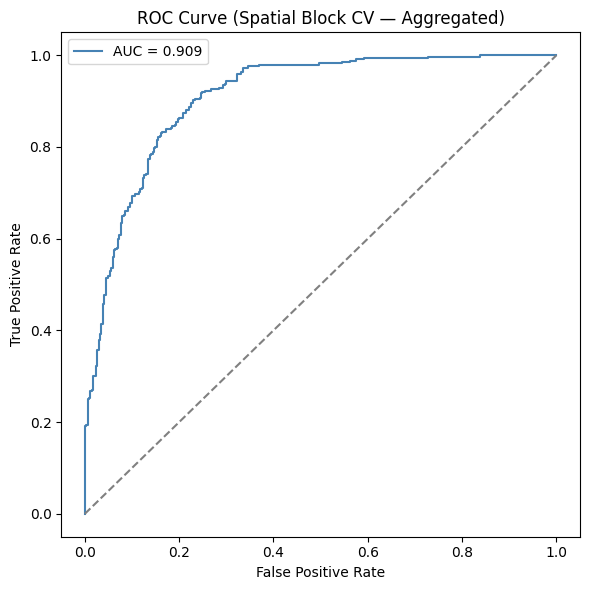

In [93]:
# 10 Receiver Operating Characteristic (ROC) Curve 
fpr, tpr, _ = roc_curve(all_y_test, all_y_prob)
auc_overall  = roc_auc_score(all_y_test, all_y_prob)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc_overall:.3f}", color='steelblue')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Spatial Block CV — Aggregated)")
plt.legend()
plt.tight_layout()
plt.show()


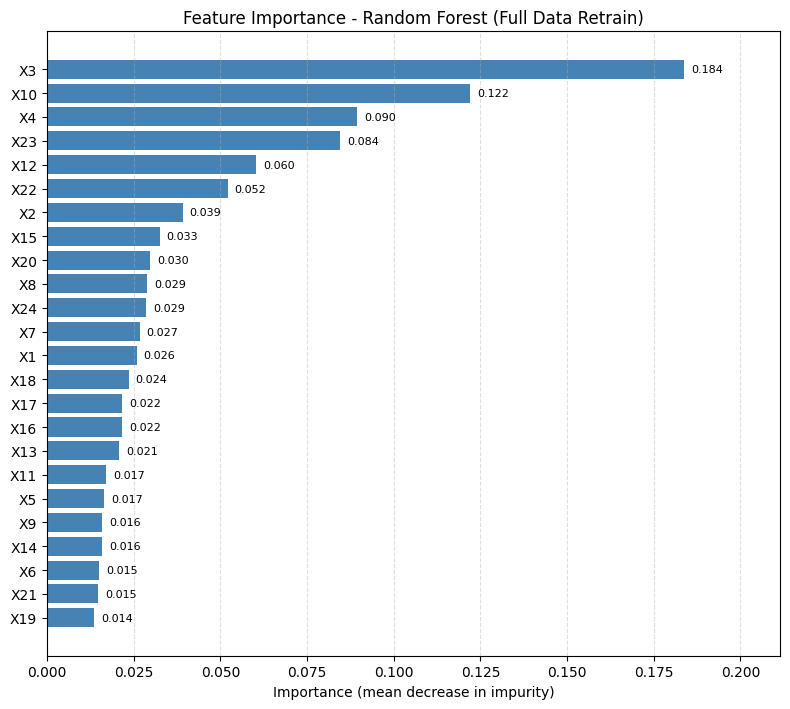

In [100]:
# 11 Feature Impoertance (as Explainble AI/XAI)

rf.fit(df_balanced[features], df_balanced["label"])

importance = pd.DataFrame({
    'feature'   : features,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

top_n = len(features)   
plot_df = importance.head(top_n).iloc[::-1]  

fig, ax = plt.subplots(figsize=(8, max(5, top_n * 0.3)))
bars = ax.barh(plot_df['feature'], plot_df['importance'], color='steelblue')

for bar, val in zip(bars, plot_df['importance']):
    ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
            f'{val:.3f}', va='center', fontsize=8)

ax.set_xlabel('Importance (mean decrease in impurity)')
ax.set_title('Feature Importance - Random Forest (Full Data Retrain)')
ax.set_xlim(0, plot_df['importance'].max() * 1.15)
ax.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

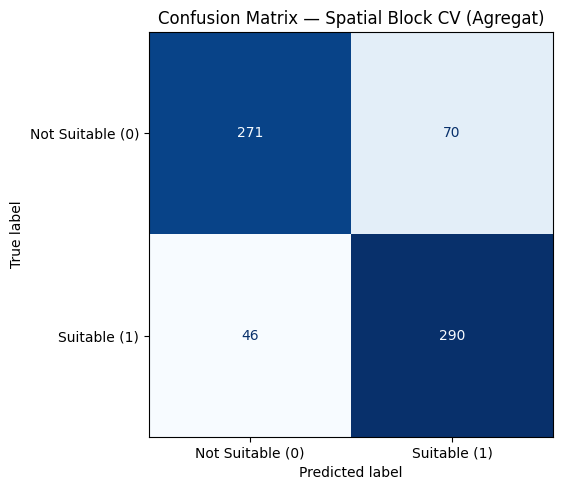

In [95]:
# 12 Confussion Matrix 
cm = confusion_matrix(all_y_test, all_y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Suitable (0)', 'Suitable (1)']
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title("Confusion Matrix — Spatial Block CV (Agregat)")
plt.tight_layout()
plt.show()

In [ ]:
# 13 Full metric report.
TN, FP, FN, TP = cm.ravel()

print("CONFUSION MATRIX")
print(f"True Negative  (TN): {TN}")
print(f"False Positive (FP): {FP}")
print(f"False Negative (FN): {FN}")
print(f"True Positive  (TP): {TP}")

print("\nEVALUATION TABLE")
print(f"{'Metrik':<15} {'Per-Fold Mean':>15} {'Per-Fold Std':>13} {'Agregat':>10}")
print("-" * 57)
print(f"{'Accuracy':<15} {np.mean(acc_scores):>15.3f} {np.std(acc_scores):>13.3f} {accuracy_score(all_y_test, all_y_pred):>10.3f}")
print(f"{'Precision':<15} {np.mean(prec_scores):>15.3f} {np.std(prec_scores):>13.3f} {precision_score(all_y_test, all_y_pred):>10.3f}")
print(f"{'Recall':<15} {np.mean(rec_scores):>15.3f} {np.std(rec_scores):>13.3f} {recall_score(all_y_test, all_y_pred):>10.3f}")
print(f"{'F1 Score':<15} {np.mean(f1_scores):>15.3f} {np.std(f1_scores):>13.3f} {f1_score(all_y_test, all_y_pred):>10.3f}")
print(f"{'ROC-AUC':<15} {np.mean(auc_scores):>15.3f} {np.std(auc_scores):>13.3f} {roc_auc_score(all_y_test, all_y_prob):>10.3f}")

CONFUSION MATRIX
True Negative  (TN): 271
False Positive (FP): 70
False Negative (FN): 46
True Positive  (TP): 290

EVALUATION TABLE
Metrik            Per-Fold Mean  Per-Fold Std    Agregat
---------------------------------------------------------
Accuracy                  0.824         0.024      0.829
Precision                 0.774         0.092      0.806
Recall                    0.856         0.026      0.863
F1 Score                  0.811         0.060      0.833
ROC-AUC                   0.907         0.017      0.909


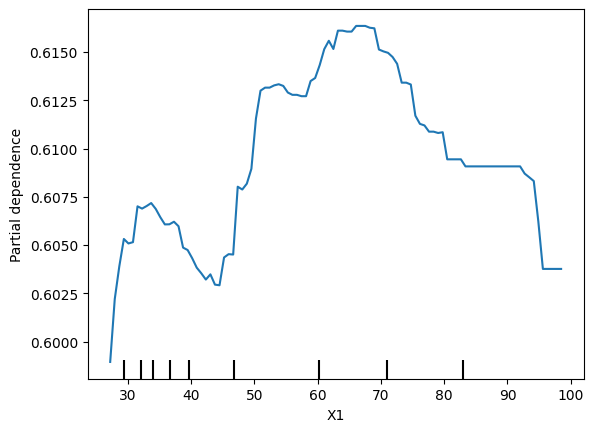

In [97]:
# 14 Partial Dependance Plot (PDP) generation (as Explainble AI/XAI)
features_inspect = ['X1'] # NOTES = this is adjustable, it can inspect another var ex: X2, X3, X19, etc.
PartialDependenceDisplay.from_estimator(rf,X_test,features_inspect)
plt.show()

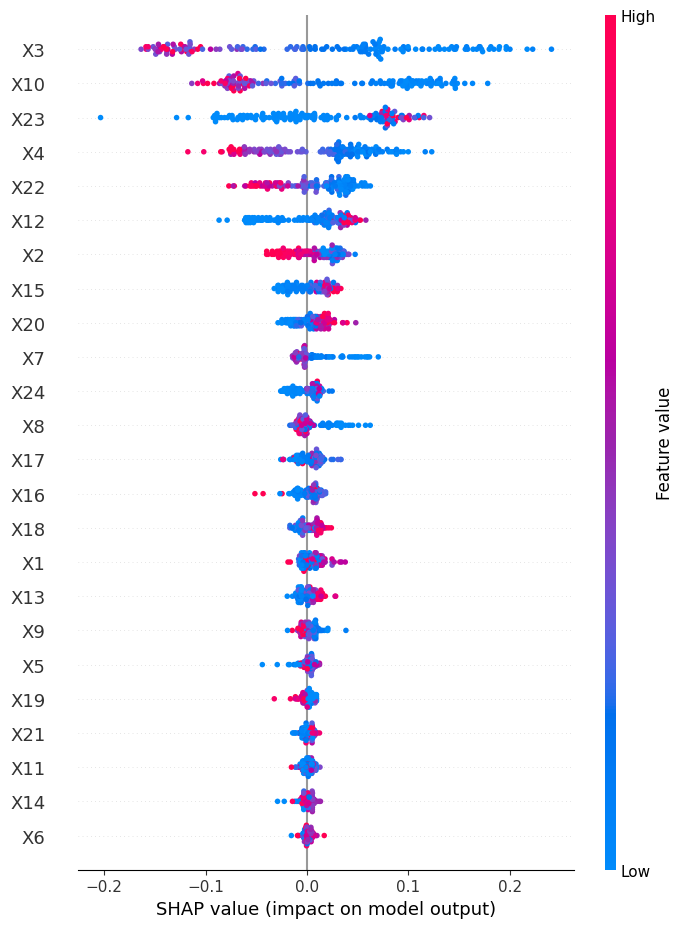

In [98]:
# 15 Shapely Additive exPlanation (SHAP) generation (as Explainble AI/XAI)
explainer = shap.TreeExplainer(rf)
shap_values = explainer(X_test)

shap_values_class1 = shap_values[:, :, 1]

plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values_class1, max_display=30)
plt.show()